In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the raw retail sales dataset
df = pd.read_csv("D:/week 2/dataset/raw/retail_store_sales.csv")

# Display the first five rows
display(df.head())


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              11362 non-null  object 
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(8)
memory usage: 1.1+ MB


In [9]:
df.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [13]:

# Step 5: Check data consistency

# Check unique values in important categorical columns
print("Category values:")
print(df["Category"].value_counts(dropna=False))

print("\nPayment Method values:")
print(df["Payment Method"].value_counts(dropna=False))

print("\nDiscount Applied values:")
print(df["Discount Applied"].value_counts(dropna=False))

# Check date format and invalid dates
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

print("\nInvalid or missing transaction dates:")
print(df["Transaction Date"].isna().sum())

# Check whether Total Spent matches Quantity × Price Per Unit
valid_rows = df[
    df["Quantity"].notna()
    & df["Price Per Unit"].notna()
    & df["Total Spent"].notna()
]

calculated_total = (
    valid_rows["Quantity"] * valid_rows["Price Per Unit"]
)

mismatch = ~np.isclose(
    valid_rows["Total Spent"],
    calculated_total,
    equal_nan=False
)

print("\nRows checked for total consistency:", len(valid_rows))
print("Rows where totals do not match:", mismatch.sum())


Category values:
Category
Electric household essentials         1591
Furniture                             1591
Food                                  1588
Milk Products                         1584
Butchers                              1568
Beverages                             1567
Computers and electric accessories    1558
Patisserie                            1528
Name: count, dtype: int64

Payment Method values:
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

Discount Applied values:
Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64

Invalid or missing transaction dates:
0

Rows checked for total consistency: 11362
Rows where totals do not match: 0


In [14]:

# Create a separate copy for cleaning
clean_df = df.copy()

# Fill missing item names
clean_df["Item"] = clean_df["Item"].fillna("Unknown")

# Fill missing numerical values using the median
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

# Keep missing discounts separate from True and False
clean_df["Discount Applied"] = (
    clean_df["Discount Applied"].fillna("Unknown")
)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

print("\nTotal missing values remaining:",
      clean_df.isnull().sum().sum())

# Check the cleaned dataset size
print("\nCleaned dataset shape:", clean_df.shape)


Missing values after cleaning:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64

Total missing values remaining: 0

Cleaned dataset shape: (12575, 11)


In [15]:

# Step 7: Check and correct data types

# Convert transaction date to datetime
clean_df["Transaction Date"] = pd.to_datetime(
    clean_df["Transaction Date"],
    errors="coerce"
)

# Convert numerical columns to numeric types
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

# Display data types after conversion
print("Data types after conversion:")
print(clean_df.dtypes)

# Check dataset information
print("\nUpdated dataset information:")
clean_df.info()


Data types after conversion:
Transaction ID              object
Customer ID                 object
Category                    object
Item                        object
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied            object
dtype: object

Updated dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    12575 non-null  object        
 1   Customer ID       12575 non-null  object        
 2   Category          12575 non-null  object        
 3   Item              12575 non-null  object        
 4   Price Per Unit    12575 non-null  float64       
 5   Quantity          12575 non-null  float64       
 

In [16]:

# Step 8: Detect outliers using the IQR method

numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

for column in numeric_columns:
    Q1 = clean_df[column].quantile(0.25)
    Q3 = clean_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    )

    print(f"\n{column}")
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", outliers.sum())



Price Per Unit
Lower limit: -13.0
Upper limit: 59.0
Number of outliers: 0

Quantity
Lower limit: -4.5
Upper limit: 15.5
Number of outliers: 0

Total Spent
Lower limit: -138.5
Upper limit: 377.5
Number of outliers: 157


In [17]:

# Identify potential outliers in Total Spent

Q1 = clean_df["Total Spent"].quantile(0.25)
Q3 = clean_df["Total Spent"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_rows = clean_df[
    (clean_df["Total Spent"] < lower_limit) |
    (clean_df["Total Spent"] > upper_limit)
]

print("Total potential outliers:", len(outlier_rows))
print("\nFirst 10 outlier rows:")

display(
    outlier_rows[
        ["Category", "Item", "Price Per Unit",
         "Quantity", "Total Spent"]
    ].head(10)
)


Total potential outliers: 157

First 10 outlier rows:


,Category,Item,Price Per Unit,Quantity,Total Spent
27,Furniture,Item_25_FUR,41.0,10.0,410.0
120,Milk Products,Item_23_MILK,38.0,10.0,380.0
129,Food,Item_24_FOOD,39.5,10.0,395.0
133,Furniture,Item_25_FUR,41.0,10.0,410.0
135,Milk Products,Item_24_MILK,39.5,10.0,395.0
146,Food,Item_24_FOOD,39.5,10.0,395.0
339,Food,Item_25_FOOD,41.0,10.0,410.0
485,Electric household essentials,Item_23_EHE,38.0,10.0,380.0
668,Butchers,Unknown,23.0,10.0,380.0
869,Beverages,Item_25_BEV,41.0,10.0,410.0


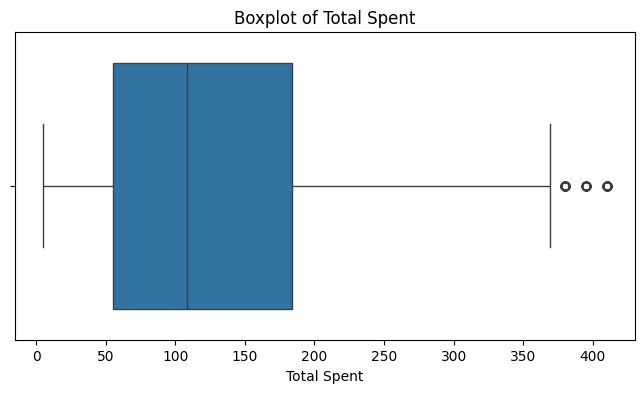

In [18]:

plt.figure(figsize=(8, 4))
sns.boxplot(x=clean_df["Total Spent"])
plt.title("Boxplot of Total Spent")
plt.xlabel("Total Spent")
plt.show()


In [22]:

# Investigate potential outliers in Total Spent

Q1 = clean_df["Total Spent"].quantile(0.25)
Q3 = clean_df["Total Spent"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = clean_df[
    (clean_df["Total Spent"] < lower_limit) |
    (clean_df["Total Spent"] > upper_limit)
]

print("Number of potential outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

display(
    outliers[
        ["Transaction ID", "Category", "Item",
         "Price Per Unit", "Quantity", "Total Spent"]
    ].head(20)
)


Number of potential outliers: 157
Lower limit: -138.5
Upper limit: 377.5


,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent
27,TXN_1599706,Furniture,Item_25_FUR,41.0,10.0,410.0
120,TXN_8215469,Milk Products,Item_23_MILK,38.0,10.0,380.0
129,TXN_1112365,Food,Item_24_FOOD,39.5,10.0,395.0
133,TXN_2953434,Furniture,Item_25_FUR,41.0,10.0,410.0
135,TXN_1249742,Milk Products,Item_24_MILK,39.5,10.0,395.0
146,TXN_2565828,Food,Item_24_FOOD,39.5,10.0,395.0
339,TXN_4374445,Food,Item_25_FOOD,41.0,10.0,410.0
485,TXN_4412300,Electric household essentials,Item_23_EHE,38.0,10.0,380.0
668,TXN_5476798,Butchers,Unknown,23.0,10.0,380.0
869,TXN_1814138,Beverages,Item_25_BEV,41.0,10.0,410.0


In [23]:

# Display the largest sales transactions

display(
    clean_df.sort_values(
        by="Total Spent",
        ascending=False
    )[
        ["Transaction ID", "Category", "Item",
         "Price Per Unit", "Quantity", "Total Spent"]
    ].head(20)
)

# Check the minimum and maximum sales values
print("Minimum Total Spent:", clean_df["Total Spent"].min())
print("Maximum Total Spent:", clean_df["Total Spent"].max())

# Check if sales values are negative
print(
    "Negative Total Spent values:",
    (clean_df["Total Spent"] < 0).sum()
)


,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent
8611,TXN_3342443,Butchers,Item_25_BUT,41.0,10.0,410.0
1060,TXN_3710081,Furniture,Item_25_FUR,41.0,10.0,410.0
8596,TXN_2288041,Food,Unknown,23.0,10.0,410.0
1088,TXN_1273334,Beverages,Item_25_BEV,41.0,10.0,410.0
11610,TXN_6812555,Beverages,Item_25_BEV,41.0,10.0,410.0
1983,TXN_6924479,Patisserie,Item_25_PAT,41.0,10.0,410.0
11608,TXN_7169895,Food,Item_25_FOOD,41.0,10.0,410.0
133,TXN_2953434,Furniture,Item_25_FUR,41.0,10.0,410.0
6611,TXN_7056530,Food,Item_25_FOOD,41.0,10.0,410.0
11662,TXN_5870737,Computers and electric accessories,Item_25_CEA,41.0,10.0,410.0


Minimum Total Spent: 5.0
Maximum Total Spent: 410.0
Negative Total Spent values: 0


In [24]:

# Recalculate Total Spent when quantity and price are available

can_calculate = (
    clean_df["Quantity"].notna()
    & clean_df["Price Per Unit"].notna()
)

# Use the calculated total for these rows
clean_df.loc[can_calculate, "Total Spent"] = (
    clean_df.loc[can_calculate, "Quantity"]
    * clean_df.loc[can_calculate, "Price Per Unit"]
)

print("Rows with available quantity and price:", can_calculate.sum())
print("Missing Total Spent values:", clean_df["Total Spent"].isna().sum())

# Check consistency
valid_rows = clean_df[
    clean_df["Quantity"].notna()
    & clean_df["Price Per Unit"].notna()
    & clean_df["Total Spent"].notna()
]

mismatch_count = (
    ~np.isclose(
        valid_rows["Total Spent"],
        valid_rows["Quantity"] * valid_rows["Price Per Unit"]
    )
).sum()

print("Remaining total calculation mismatches:", mismatch_count)


Rows with available quantity and price: 12575
Missing Total Spent values: 0
Remaining total calculation mismatches: 0


In [30]:


# Improved before-and-after cleaning report

cleaning_report = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing cells",
        "Duplicate rows",
        "Potential outliers detected",
        "Outliers removed"
    ],
    "Before Cleaning": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        157,
        0
    ],
    "After Cleaning": [
        clean_df.shape[0],
        clean_df.shape[1],
        clean_df.isnull().sum().sum(),
        clean_df.duplicated().sum(),
        157,
        0
    ]
})

display(cleaning_report)

cleaning_report.to_csv(
    "../reports/data_cleaning_summary.csv",
    index=False
)

print("Updated cleaning report saved successfully!")


print("Cleaning report saved successfully!")


,Metric,Before Cleaning,After Cleaning
0,Rows,12575,12575
1,Columns,11,11
2,Missing cells,7229,0
3,Duplicate rows,0,0
4,Potential outliers detected,157,157
5,Outliers removed,0,0


Updated cleaning report saved successfully!
Cleaning report saved successfully!


In [29]:
# Step 10: Save the cleaned dataset

import os

# Create the cleaned folder if it does not exist
os.makedirs("../dataset/cleaned", exist_ok=True)

# Save the cleaned dataset
output_path = "../dataset/cleaned/retail_sales_cleaned.csv"

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)
print("Cleaned dataset shape:", clean_df.shape)

# Verify the saved file
verified_df = pd.read_csv(output_path)

print("\nSaved file shape:", verified_df.shape)
print("Missing values in saved file:",
      verified_df.isnull().sum().sum())

Cleaned dataset saved successfully!
File location: ../dataset/cleaned/retail_sales_cleaned.csv
Cleaned dataset shape: (12575, 11)

Saved file shape: (12575, 11)
Missing values in saved file: 0
